# Figure 2
ODE and stochastic molecular model implementation examples

#### Load libraries
Add paths to PySB models in Python folder

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, "../../Python/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, "../../Python/fit")

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from cell_cycle_death_model import model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    


## Fig2b


In [3]:
#change the model parameters of the model if needed
# omega = 200

# Directory containing cell fate data
DATADIR = Path('../../Data/Exp_Intermitotic_Times/')

In [4]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)
size = (3.5, 2.5)

In [5]:
#ODE simulation

t = np.linspace(0, 500, 50001)
simres = ScipyOdeSimulator(model, t, verbose=False).run(); #deterministic simulation
yout = simres.all;


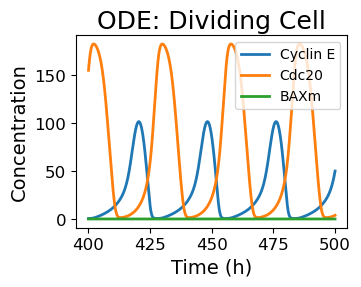

In [6]:
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and BAXm
label=['Cyclin E', 'Cdc20', 'BAXm']


fig= plt.figure(figsize=size)
for obs in range(3) :
    plt.plot(t[40000:],yout[observables[obs]][40000:], label=label[obs], lw=2)
plt.legend(loc=1)
plt.xlabel('Time (h)')
plt.ylabel('Concentration')
plt.title('ODE: Dividing Cell')

fig2b_fn = Path(SAVEDIR, 'fig2b.svg')

if SAVEFILES and (OVERWRITE or not fig2b_fn.exists()):
    plt.savefig(fig2b_fn, bbox_inches='tight')
else:
    plt.figure()

In [7]:
%%time

### Stochastic simulation

t = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33); #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim


CPU times: user 748 ms, sys: 61 ms, total: 809 ms
Wall time: 3.25 s


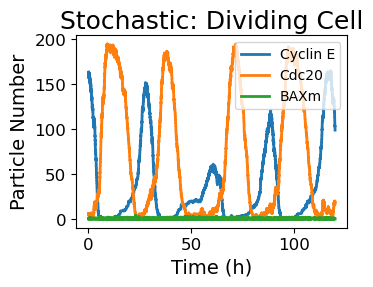

In [8]:
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and Cyclin A
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t,yout[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=1)
plt.xlabel('Time (h)')
plt.ylabel('Particle Number')
plt.title('Stochastic: Dividing Cell')


fig2c_fn = Path(SAVEDIR, 'fig2c.svg')
if SAVEFILES and (OVERWRITE or not fig2c_fn.exists()):
    plt.savefig(fig2c_fn, bbox_inches='tight')
else:
    plt.figure()

### Set input parameter values to soft_ERL condition

In [9]:
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4
model.parameters['AKT'].value = 0.3

In [10]:
%%time

### Stochastic simulation

t = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=3); #running the simulation; remove seed for truly random; seed=3 used for quiescent cell


CPU times: user 742 ms, sys: 56.7 ms, total: 798 ms
Wall time: 3.16 s


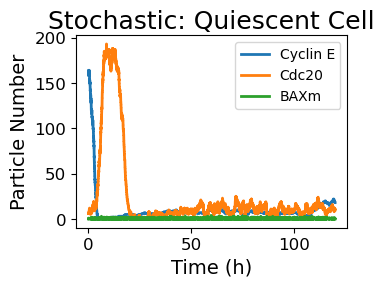

In [11]:
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and BAXm
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t,yout[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=0)
plt.xlabel('Time (h)')
plt.ylabel('Particle Number')
plt.title('Stochastic: Quiescent Cell')


fig2d_fn = Path(SAVEDIR, 'fig2d.svg')
if SAVEFILES and (OVERWRITE or not fig2d_fn.exists()):
    plt.savefig(fig2d_fn, bbox_inches='tight')
else:
    plt.figure()

In [12]:
%%time

### Stochastic simulation

t = np.linspace(0, 120, 120001);
sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=13); #running the simulation; remove seed for truly random; seed=5 or 13 is used for dying cell


CPU times: user 740 ms, sys: 60.3 ms, total: 800 ms
Wall time: 3.19 s


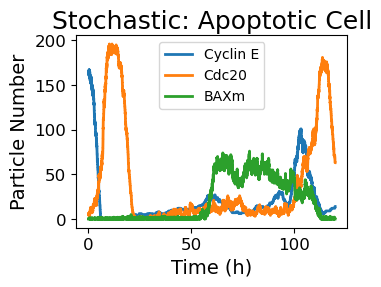

In [13]:
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsBAXm']; #plot Cyclin E, Cdc20 and Cyclin A
label=['Cyclin E', 'Cdc20', 'BAXm']

fig = plt.figure(figsize=size)
for obs in range(3) :    
    plt.plot(t,yout[observables[obs]], label=label[obs], lw=2)
plt.legend(loc=0)
plt.xlabel('Time (h)')
plt.ylabel('Particle Number')
plt.title('Stochastic: Apoptotic Cell')


fig2e_fn = Path(SAVEDIR, 'fig2e.svg')
if SAVEFILES and (OVERWRITE or not fig2e_fn.exists()):
    plt.savefig(fig2e_fn, bbox_inches='tight')
else:
    plt.figure()